# F25 — Taux directeur et pente de la courbe

**Nom et prénom :** Edjang Alene    **Code Apogée :** 23009441    **Groupe :** G3Fin    **Filière :** S7 FIN    **Date :** 26/11/2026

**Dépôt GitHub :** https://github.com/MariaprincesaMangue/23009441-EdjangAlene-G3Fin

## 1. Sujet et problématique
- **Intérêt du sujet :** La pente de la courbe des taux (écart entre les rendements obligataires à long terme et à court terme) est un baromètre central des anticipations macroéconomiques et du coût de financement de l'État. Comprendre comment elle réagit aux décisions de politique monétaire de Bank Al-Maghrib (BAM) est essentiel pour les gérants obligataires, les trésoriers bancaires et les décideurs publics.
- **Problématique :** Dans quelle mesure le niveau du taux directeur de Bank Al-Maghrib permet-il d'expliquer et de prévoir la pente de la courbe des taux des Bons du Trésor marocains (10 ans moins 2 ans) sur la période 2018–2026 ?
- **Objectif mesurable :** Prévoir la pente mensuelle de la courbe des taux ($\text{Taux}_{10\text{ ans}} - \text{Taux}_{2\text{ ans}}$) sur les 14 dernières observations (août 2024 à mars 2026) avec une erreur absolue moyenne (MAE) inférieure d'au moins 10 % à celle d'une référence naïve (moyenne historique de l'apprentissage).
- **Nature du problème :** Problème d'apprentissage supervisé de **régression** sur série temporelle, car la variable cible ($\text{Pente}_t$, exprimée en points de pourcentage) est continue et datée mensuellement.
- **Algorithme principal envisagé :** Algorithme `1` de l'annexe A — **Régression linéaire** (`LinearRegression`), avec l'algorithme `2` (**Ridge**) en comparaison facultative.


In [5]:
import os
import sys
import glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import statsmodels
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Fixation de la graine aléatoire pour la reproductibilité
GRAINE = 42
np.random.seed(GRAINE)

print(f"Python : {sys.version.split()[0]}")
print(f"pandas : {pd.__version__} | numpy : {np.__version__} | sklearn : {sklearn.__version__} | statsmodels : {statsmodels.__version__}")

Python : 3.13.18
pandas : 2.2.3 | numpy : 2.4.6 | sklearn : 1.6.1 | statsmodels : 0.15.0


## 2. Jeu de données
- **Sources et liens d'accès (date d'extraction : 26/11/2026) :**
  1. *Historique des décisions de politique monétaire (Taux directeur)* — Bank Al-Maghrib : `https://www.bkam.ma/Politique-monetaire/Cadre-strategique/Decision-de-la-politique-monetaire/Historique-des-decisions`
  2. *Taux moyens pondérés mensuels des émissions du Trésor (TMP)* — Bank Al-Maghrib : `https://www.bkam.ma/Marches/Principaux-indicateurs/Marche-obligataire/Marche-des-bons-de-tresor/Marche-des-adjudications-des-bons-de-tresor/Taux-moyens-ponderes-mensuels-des-emissions-du-tresor`
- **Licence et conditions d'utilisation :** Données publiques officielles diffusées librement par Bank Al-Maghrib ; utilisation académique autorisée sans restriction mentionnée.
- **Taille et fréquence :** Le fichier des décisions contient 77 réunions (décembre 2006 à mars 2026). Le fichier des émissions du Trésor couvre 106 mois (janvier 2018 à octobre 2026). Après calcul de la pente (`10 ans` et `2 ans` émis simultanément), l'échantillon final comprend **66 observations mensuelles** (février 2018 à mars 2026).
- **Unité d'observation :** Une fin de mois calendaire correspondant aux adjudications mensuelles du Trésor marocain.
- **Variable cible :** $\text{Pente}_t = \text{Taux}_{10\text{ ans}, t} - \text{Taux}_{2\text{ ans}, t}$ (en points de pourcentage).
- **Adéquation et limites :** Ce jeu couvre trois régimes monétaires distincts au Maroc (baisse Covid à 1,50 % en 2020, resserrement à 3,00 % en 2023, assouplissement à 2,25 % en 2025–2026). Toutefois, sur le marché primaire, le Trésor n'émet pas systématiquement du 10 ans chaque mois (38 absences sur 106 mois), réduisant la série exploitable à 66 mois.

| Variable | Description | Type | Unité | Rôle | Manquants (%) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| `Date` | Date de fin de mois de l'observation | Date | AAAA-MM-JJ | Date / Index | 0,0 % |
| `Taux_directeur` | Taux directeur de Bank Al-Maghrib en vigueur à la date $t$ | Numérique | % | Explicative ($X$) | 0,0 % |
| `2 ans` | Taux moyen pondéré mensuel des BdT à 2 ans | Numérique | % | Composante cible | 5,7 % |
| `10 ans` | Taux moyen pondéré mensuel des BdT à 10 ans | Numérique | % | Composante cible | 35,8 % |
| `Pente_10_2` | Écart de rendement $\text{Taux}_{10\text{ ans}} - \text{Taux}_{2\text{ ans}}$ | Numérique | Points de % | Cible ($Y$) | 37,7 % (avant filtrage) |

In [4]:
import os
import sys
import glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import statsmodels
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Fixation de la graine aléatoire pour la reproductibilité
GRAINE = 42
np.random.seed(GRAINE)

print(f"Python : {sys.version.split()[0]}")
print(f"pandas : {pd.__version__} | numpy : {np.__version__} | sklearn : {sklearn.__version__} | statsmodels : {statsmodels.__version__}")

Python : 3.13.18
pandas : 2.2.3 | numpy : 2.4.6 | sklearn : 1.6.1 | statsmodels : 0.15.0


## 2. Jeu de données
- **Sources et liens d'accès (date d'extraction : 26/11/2026) :**
  1. *Historique des décisions de politique monétaire (Taux directeur)* — Bank Al-Maghrib : `https://www.bkam.ma/Politique-monetaire/Cadre-strategique/Decision-de-la-politique-monetaire/Historique-des-decisions`
  2. *Taux moyens pondérés mensuels des émissions du Trésor (TMP)* — Bank Al-Maghrib : `https://www.bkam.ma/Marches/Principaux-indicateurs/Marche-obligataire/Marche-des-bons-de-tresor/Marche-des-adjudications-des-bons-de-tresor/Taux-moyens-ponderes-mensuels-des-emissions-du-tresor`
- **Licence et conditions d'utilisation :** Données publiques officielles diffusées librement par Bank Al-Maghrib ; utilisation académique autorisée sans restriction mentionnée.
- **Taille et fréquence :** Le fichier des décisions contient 77 réunions (décembre 2006 à mars 2026). Le fichier des émissions du Trésor couvre 106 mois (janvier 2018 à octobre 2026). Après calcul de la pente (`10 ans` et `2 ans` émis simultanément), l'échantillon final comprend **66 observations mensuelles** (février 2018 à mars 2026).
- **Unité d'observation :** Une fin de mois calendaire correspondant aux adjudications mensuelles du Trésor marocain.
- **Variable cible :** $\text{Pente}_t = \text{Taux}_{10\text{ ans}, t} - \text{Taux}_{2\text{ ans}, t}$ (en points de pourcentage).
- **Adéquation et limites :** Ce jeu couvre trois régimes monétaires distincts au Maroc (baisse Covid à 1,50 % en 2020, resserrement à 3,00 % en 2023, assouplissement à 2,25 % en 2025–2026). Toutefois, sur le marché primaire, le Trésor n'émet pas systématiquement du 10 ans chaque mois (38 absences sur 106 mois), réduisant la série exploitable à 66 mois.

| Variable | Description | Type | Unité | Rôle | Manquants (%) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| `Date` | Date de fin de mois de l'observation | Date | AAAA-MM-JJ | Date / Index | 0,0 % |
| `Taux_directeur` | Taux directeur de Bank Al-Maghrib en vigueur à la date $t$ | Numérique | % | Explicative ($X$) | 0,0 % |
| `2 ans` | Taux moyen pondéré mensuel des BdT à 2 ans | Numérique | % | Composante cible | 5,7 % |
| `10 ans` | Taux moyen pondéré mensuel des BdT à 10 ans | Numérique | % | Composante cible | 35,8 % |
| `Pente_10_2` | Écart de rendement $\text{Taux}_{10\text{ ans}} - \text{Taux}_{2\text{ ans}}$ | Numérique | Points de % | Cible ($Y$) | 37,7 % (avant filtrage) |

In [6]:
# Clonage du dépôt GitHub si nécessaire (exécution autonome dans Colab)
if not os.path.exists("23009441-EdjangAlene-G3Fin") and not os.path.exists("data/raw"):
    !git clone https://github.com/MariaprincesaMangue/23009441-EdjangAlene-G3Fin.git

if os.path.exists("23009441-EdjangAlene-G3Fin"):
    %cd /content/23009441-EdjangAlene-G3Fin

# Création des dossiers de sortie avec chemins relatifs
Path("figures").mkdir(parents=True, exist_ok=True)
Path("data/processed").mkdir(parents=True, exist_ok=True)

# Détection automatique du fichier du taux directeur dans data/raw/
fichiers_td = glob.glob("data/raw/*taux*directeur*.csv") + glob.glob("data/raw/*Taux*Directeur*.csv")
chemin_td = fichiers_td[0]

# Vérification de la présence d'une ligne de titre avant l'en-tête
with open(chemin_td, "r", encoding="utf-8", errors="ignore") as f:
    premiere_ligne = f.readline()
lignes_a_ignorer = 0 if "Date" in premiere_ligne else 1

# Chargement des données brutes
raw_td = pd.read_csv(chemin_td, sep=";", skiprows=lignes_a_ignorer)
raw_td.columns = ["Date", "Taux directeur"]

raw_bdt = pd.read_csv(
    "data/raw/Taux-moyens-ponderes-mensuels-des-emissions-du-tresor_26_11_2026-15_50.csv",
    sep=";",
    skiprows=2
)

print("Fichier Taux Directeur chargé :", chemin_td, "| Dimensions :", raw_td.shape)
print("Dimensions brutes Bons du Trésor :", raw_bdt.shape)
display(raw_td.head(3))
display(raw_bdt.head(3))

Fichier Taux Directeur chargé : data/raw/taux_directeur_bam_ordonne.csv | Dimensions : (77, 2)
Dimensions brutes Bons du Trésor : (106, 10)


,Date,Taux directeur
0,19/12/2006,3.25
1,27/03/2007,3.25
2,19/06/2007,3.25


,Date/Maturités,13 semaines,26 semaines,52 semaines,2 ans,5 ans,10 ans,15 ans,20 ans,30 ans
0,octobre-2026,"2,170 %","2,215 %","2,358 %","2,475 %","2,978 %",-,-,-,-
1,septembre-2026,-,-,"2,231 %","2,418 %","2,900 %",-,-,-,-
2,août-2026,-,"2,155 %","2,210 %","2,391 %","2,858 %",-,-,-,-


## 3. Exploration

Nombre de doublons sur la colonne Date : 0


,Taux_directeur,2 ans,10 ans,Pente_10_2
count,66.0000,66.0000,66.0000,66.0000
mean,2.2652,2.5315,3.1384,0.6069
std,0.5186,0.6017,0.6392,0.1241
min,1.5000,1.6610,2.2930,0.2290
25%,2.2500,2.0900,2.6442,0.5412
50%,2.2500,2.4500,3.1325,0.6120
75%,2.7500,2.8222,3.4825,0.7000
max,3.0000,3.8550,4.6470,0.8940


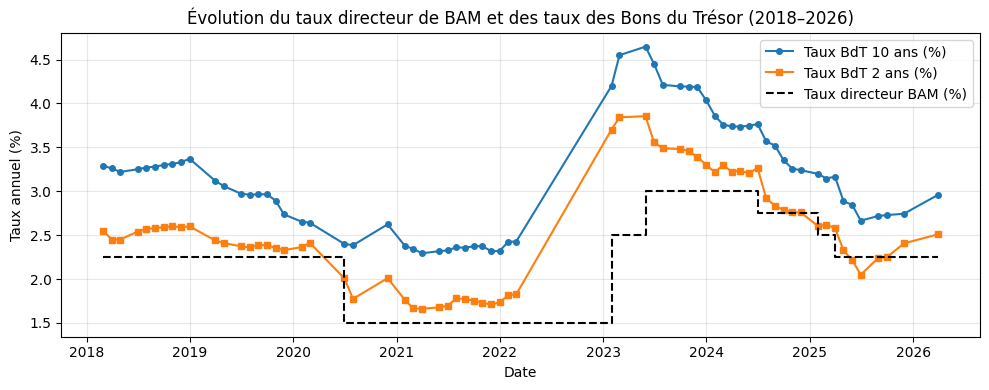

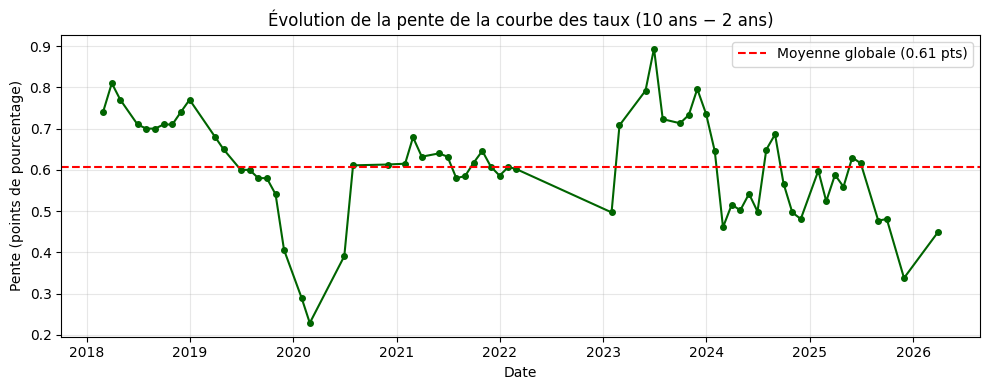

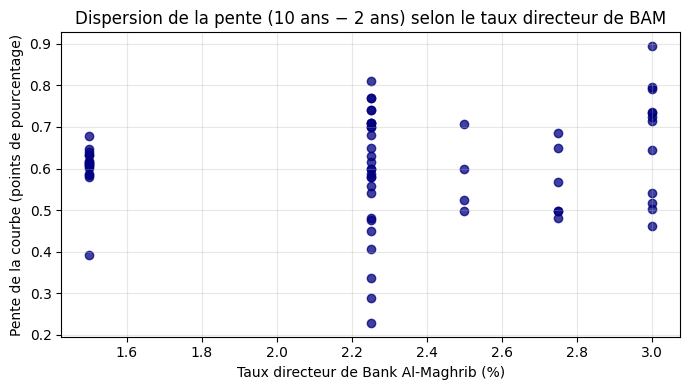

In [7]:
# Mise en forme des types numériques et dates pour l'exploration
df_td = raw_td[["Date", "Taux directeur"]].dropna().copy()
df_td["Date"] = pd.to_datetime(df_td["Date"], format="%d/%m/%Y")
df_td["Taux_directeur"] = (
    df_td["Taux directeur"]
    .astype(str)
    .str.replace("%", "", regex=False)
    .str.replace(",", ".", regex=False)
    .str.strip()
    .astype(float)
)
df_td = df_td.sort_values("Date").reset_index(drop=True)

df_bdt = raw_bdt.copy()
for col in df_bdt.columns[1:]:
    df_bdt[col] = (
        df_bdt[col]
        .astype(str)
        .str.replace("%", "", regex=False)
        .str.replace(",", ".", regex=False)
        .str.strip()
        .replace("-", np.nan)
    )
    df_bdt[col] = pd.to_numeric(df_bdt[col], errors="coerce")

mois_fr = {
    'janvier': 1, 'février': 2, 'mars': 3, 'avril': 4, 'mai': 5, 'juin': 6,
    'juillet': 7, 'août': 8, 'septembre': 9, 'octobre': 10, 'novembre': 11, 'décembre': 12
}
df_bdt["Date"] = df_bdt["Date/Maturités"].apply(
    lambda s: pd.Timestamp(year=int(s.split('-')[1]), month=mois_fr[s.split('-')[0].lower()], day=1) + pd.offsets.MonthEnd(1)
)
df_bdt = df_bdt.sort_values("Date").reset_index(drop=True)
df_bdt["Pente_10_2"] = df_bdt["10 ans"] - df_bdt["2 ans"]

# Fusion causale (uniquement les décisions passées ou contemporaines)
df_all = pd.merge_asof(df_bdt, df_td[["Date", "Taux_directeur"]], on="Date", direction="backward")
df = df_all.dropna(subset=["Pente_10_2", "Taux_directeur"]).reset_index(drop=True)

print("Nombre de doublons sur la colonne Date :", df["Date"].duplicated().sum())
display(df[["Taux_directeur", "2 ans", "10 ans", "Pente_10_2"]].describe().round(4))

# Graphique 1 : Évolution temporelle des taux (2 ans, 10 ans et Taux directeur)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df["Date"], df["10 ans"], marker="o", markersize=4, label="Taux BdT 10 ans (%)")
ax.plot(df["Date"], df["2 ans"], marker="s", markersize=4, label="Taux BdT 2 ans (%)")
ax.step(df["Date"], df["Taux_directeur"], where="post", linestyle="--", color="black", label="Taux directeur BAM (%)")
ax.set_title("Évolution du taux directeur de BAM et des taux des Bons du Trésor (2018–2026)")
ax.set_xlabel("Date")
ax.set_ylabel("Taux annuel (%)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("figures/fig1_evolution_taux.png", dpi=150)
plt.show()

# Graphique 2 : Évolution de la pente de la courbe (10 ans - 2 ans)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df["Date"], df["Pente_10_2"], color="darkgreen", marker="o", markersize=4)
ax.axhline(df["Pente_10_2"].mean(), color="red", linestyle="--", label=f"Moyenne globale ({df['Pente_10_2'].mean():.2f} pts)")
ax.set_title("Évolution de la pente de la courbe des taux (10 ans − 2 ans)")
ax.set_xlabel("Date")
ax.set_ylabel("Pente (points de pourcentage)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("figures/fig2_evolution_pente.png", dpi=150)
plt.show()

# Graphique 3 : Relation entre le Taux directeur et la Pente de la courbe
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(df["Taux_directeur"], df["Pente_10_2"], alpha=0.75, color="navy")
ax.set_title("Dispersion de la pente (10 ans − 2 ans) selon le taux directeur de BAM")
ax.set_xlabel("Taux directeur de Bank Al-Maghrib (%)")
ax.set_ylabel("Pente de la courbe (points de pourcentage)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("figures/fig3_scatter_td_pente.png", dpi=150)
plt.show()

**Interprétation des graphiques exploratoires :**
- **Graphique 1 :** Les taux à 2 ans et 10 ans suivent globalement les cycles du taux directeur (baisse en 2020 à 1,50 %, forte hausse en 2022–2023 jusqu'à 3,00 %, puis détente en 2024–2026), mais le taux à 2 ans réagit plus fortement aux décisions de BAM que le taux à 10 ans.
- **Graphique 2 :** La pente oscille entre **0,23** et **0,89** point de pourcentage (moyenne de **0,61** point) et reste toujours positive sur la période (aucune inversion de courbe). On observe un aplatissement notable fin 2025 (0,34 point).
- **Graphique 3 :** Le nuage de points montre une dispersion importante de la pente pour un même niveau du taux directeur (par exemple entre 0,34 et 0,85 point lorsque le taux directeur vaut 2,25 %), ce qui suggère une relation linéaire faible.
- **Qualité des données :** Aucun doublon n'est présent. Les mois sans émission à 10 ans (38 mois sur 106) ont été retirés plutôt qu'imputés artificiellement afin de ne pas inventer de rendements obligataires. Les valeurs extrêmes de 2023 (taux à 10 ans à 4,65 %) reflètent le pic réel d'inflation et sont conservées.

## 4. Préparation
- **Prévention des fuites de données :** Les deux séries ont été triées par ordre chronologique strict (2018 à 2026). La fusion utilise `pd.merge_asof(..., direction="backward")`, garantissant qu'à chaque mois $t$, seul le taux directeur déjà annoncé à une date $\le t$ est utilisé.
- **Découpage temporel :** L'échantillon de 66 mois est découpé chronologiquement sans mélange aléatoire (`shuffle=False`) en **80 % apprentissage** (52 mois : février 2018 à juillet 2024) et **20 % test** (14 mois : août 2024 à mars 2026).
- **Mise à l'échelle :** Avec une seule variable explicative (`Taux_directeur`) en régression linéaire ordinaire, la mise à l'échelle n'affecte ni les prédictions ni le $R^2$ et permet de conserver l'interprétation directe du coefficient en points de pourcentage.

In [8]:
# Sauvegarde des données préparées dans data/processed/
df_model = df[["Date", "Taux_directeur", "2 ans", "10 ans", "Pente_10_2"]].copy()
df_model.to_csv("data/processed/donnees_f25_preparees.csv", index=False)

# Découpage chronologique strict (80 % apprentissage / 20 % test)
split_idx = int(len(df_model) * 0.8)
train = df_model.iloc[:split_idx].copy()
test = df_model.iloc[split_idx:].copy()

X_train, y_train = train[["Taux_directeur"]], train["Pente_10_2"]
X_test, y_test = test[["Taux_directeur"]], test["Pente_10_2"]

print(f"Apprentissage : {len(train)} mois ({train['Date'].min().date()} au {train['Date'].max().date()})")
print(f"Test          : {len(test)} mois ({test['Date'].min().date()} au {test['Date'].max().date()})")
print("\nPreuve de l'alignement temporel (5 premières lignes d'apprentissage) :")
display(train.head(5))

Apprentissage : 52 mois (2018-02-28 au 2024-07-31)
Test          : 14 mois (2024-08-31 au 2026-03-31)

Preuve de l'alignement temporel (5 premières lignes d'apprentissage) :


,Date,Taux_directeur,2 ans,10 ans,Pente_10_2
0,2018-02-28,2.25,2.55,3.29,0.74
1,2018-03-31,2.25,2.45,3.26,0.81
2,2018-04-30,2.25,2.45,3.22,0.77
3,2018-06-30,2.25,2.54,3.25,0.71
4,2018-07-31,2.25,2.57,3.27,0.70


## 5. Algorithme
- **Choix de l'algorithme :** L'algorithme principal retenu est la **Régression linéaire** (`LinearRegression`, n° 1 de l'annexe A), complété par la **Régression Ridge** (`Ridge`, n° 2) en comparaison. Ce choix est adapté à une relation quantitative directe à une seule variable explicative sur un petit échantillon ($n = 52$ en apprentissage), où des modèles complexes (forêts aléatoires ou boosting) surapprendraient le bruit.
- **Principe et formule :** La régression linéaire estime la relation affine $\hat{y}_i = \beta_0 + \beta_1 x_i$, où $\hat{y}_i$ est la pente prédite (en points de %), $x_i$ le taux directeur (en %), $\beta_0$ l'ordonnée à l'origine et $\beta_1$ la pente de régression. Les paramètres appris $(\beta_0, \beta_1)$ minimisent la somme des carrés des résidus : $\min_{\beta_0, \beta_1} \sum_{i=1}^{n} (y_i - \beta_0 - \beta_1 x_i)^2$.
- **Hyperparamètres :** `LinearRegression` ne possède pas d'hyperparamètre de régularisation (seulement `fit_intercept=True`). Pour `Ridge`, l'hyperparamètre $\alpha > 0$ pénalise la norme $L_2$ du coefficient ($\alpha \beta_1^2$), réduisant la variance lorsque $\alpha$ augmente.

## 6. Protocole expérimental
- **Découpage et validation :** Apprentissage sur 52 mois (02/2018–07/2024), validation croisée temporelle sur l'apprentissage avec `TimeSeriesSplit(n_splits=5)` (5 configurations testées pour `Ridge` : $\alpha \in \{0,01; 0,1; 1; 10; 100\}$), et évaluation finale unique sur les 14 mois de test (08/2024–03/2026).
- **Référence naïve :** Prédiction constante égale à la moyenne historique de la pente sur l'échantillon d'apprentissage ($\bar{y}_{\text{train}} = 0,626$ point de %).
- **Métriques :** La métrique principale est la **MAE** (*Mean Absolute Error*, en points de %), car elle mesure l'erreur moyenne directement dans l'unité de la pente sans amplifier excessivement les mois atypiques. Les métriques secondaires sont le **RMSE** (en points de %) et le **$R^2$** (part de variance expliquée).

Équation apprise : Pente = 0.5418 + 0.0380 * Taux_directeur
Validation croisée (5 plis) — Naïf MAE : 0.1112 ± 0.0800
Validation croisée (5 plis) — LR   MAE : 0.1150 ± 0.0814
Meilleur alpha Ridge : 100.0
P-valeur du coefficient Taux_directeur (train) : 0.2246


,Modèle,MAE Train,MAE CV (moy ± std),MAE Test,RMSE Test,R2 Test
0,Référence naïve (moyenne),0.0923,0.1112 ± 0.0800,0.1002,0.1253,-1.1226
1,Régression linéaire (n° 1),0.0903,0.1150 ± 0.0814,0.1051,0.1302,-1.2922
2,Ridge réglé (n° 2),0.0915,0.1113,0.1009,0.1259,-1.1443


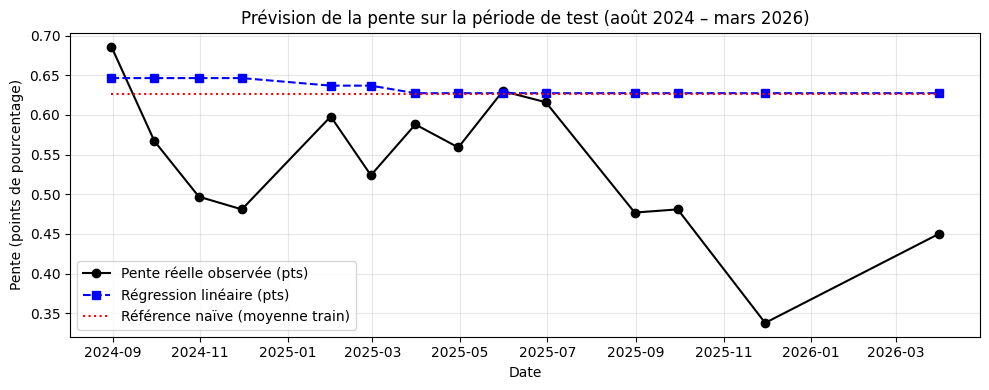


Les 3 plus fortes erreurs sur le test :


,Date,Taux_directeur,Pente_10_2,Prediction_LR,Erreur_Absolue
64,2025-11-30,2.25,0.338,0.6274,0.2894
65,2026-03-31,2.25,0.450,0.6274,0.1774
55,2024-11-30,2.75,0.481,0.6464,0.1654



Illustration d'usage sur 4 observations de test non vues à l'apprentissage :


,Date,Taux_directeur,Pente_10_2,Prediction_LR,Erreur_Absolue
52,2024-08-31,2.75,0.686,0.6464,0.0396
53,2024-09-30,2.75,0.567,0.6464,0.0794
54,2024-10-31,2.75,0.497,0.6464,0.1494
55,2024-11-30,2.75,0.481,0.6464,0.1654


In [9]:
# 1. Référence naïve (moyenne historique sur l'apprentissage)
y_pred_naive_train = np.full(len(y_train), y_train.mean())
y_pred_naive_test = np.full(len(y_test), y_train.mean())

# 2. Modèle principal : Régression linéaire (n° 1)
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr_train = lr.predict(X_train)
y_pred_lr_test = lr.predict(X_test)

# 3. Modèle de comparaison : Ridge réglé par TimeSeriesSplit (n° 2)
tscv = TimeSeriesSplit(n_splits=5)
grid_ridge = GridSearchCV(
    Ridge(),
    param_grid={"alpha": [0.01, 0.1, 1.0, 10.0, 100.0]},
    cv=tscv,
    scoring="neg_mean_absolute_error"
)
grid_ridge.fit(X_train, y_train)
y_pred_ridge_test = grid_ridge.predict(X_test)

# Calcul de l'incertitude en validation croisée temporelle
cv_mae_naive, cv_mae_lr = [], []
for tr_i, val_i in tscv.split(X_train):
    m = LinearRegression().fit(X_train.iloc[tr_i], y_train.iloc[tr_i])
    cv_mae_lr.append(mean_absolute_error(y_train.iloc[val_i], m.predict(X_train.iloc[val_i])))
    cv_mae_naive.append(mean_absolute_error(y_train.iloc[val_i], np.full(len(val_i), y_train.iloc[tr_i].mean())))

print(f"Équation apprise : Pente = {lr.intercept_:.4f} + {lr.coef_[0]:.4f} * Taux_directeur")
print(f"Validation croisée (5 plis) — Naïf MAE : {np.mean(cv_mae_naive):.4f} ± {np.std(cv_mae_naive):.4f}")
print(f"Validation croisée (5 plis) — LR   MAE : {np.mean(cv_mae_lr):.4f} ± {np.std(cv_mae_lr):.4f}")
print(f"Meilleur alpha Ridge : {grid_ridge.best_params_['alpha']}")

# Test de significativité statistique (statsmodels) sur l'apprentissage
ols_res = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(f"P-valeur du coefficient Taux_directeur (train) : {ols_res.pvalues['Taux_directeur']:.4f}")

# Tableau comparatif final
resultats = pd.DataFrame({
    "Modèle": ["Référence naïve (moyenne)", "Régression linéaire (n° 1)", "Ridge réglé (n° 2)"],
    "MAE Train": [
        mean_absolute_error(y_train, y_pred_naive_train),
        mean_absolute_error(y_train, y_pred_lr_train),
        mean_absolute_error(y_train, grid_ridge.predict(X_train))
    ],
    "MAE CV (moy ± std)": [
        f"{np.mean(cv_mae_naive):.4f} ± {np.std(cv_mae_naive):.4f}",
        f"{np.mean(cv_mae_lr):.4f} ± {np.std(cv_mae_lr):.4f}",
        f"{-grid_ridge.best_score_:.4f}"
    ],
    "MAE Test": [
        mean_absolute_error(y_test, y_pred_naive_test),
        mean_absolute_error(y_test, y_pred_lr_test),
        mean_absolute_error(y_test, y_pred_ridge_test)
    ],
    "RMSE Test": [
        np.sqrt(mean_squared_error(y_test, y_pred_naive_test)),
        np.sqrt(mean_squared_error(y_test, y_pred_lr_test)),
        np.sqrt(mean_squared_error(y_test, y_pred_ridge_test))
    ],
    "R2 Test": [
        r2_score(y_test, y_pred_naive_test),
        r2_score(y_test, y_pred_lr_test),
        r2_score(y_test, y_pred_ridge_test)
    ]
})
display(resultats.round(4))

# Graphique 4 : Prédictions vs Réalité sur la période de test
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(test["Date"], y_test, marker="o", label="Pente réelle observée (pts)", color="black")
ax.plot(test["Date"], y_pred_lr_test, marker="s", linestyle="--", label="Régression linéaire (pts)", color="blue")
ax.plot(test["Date"], y_pred_naive_test, linestyle=":", label="Référence naïve (moyenne train)", color="red")
ax.set_title("Prévision de la pente sur la période de test (août 2024 – mars 2026)")
ax.set_xlabel("Date")
ax.set_ylabel("Pente (points de pourcentage)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("figures/fig4_resultats_test.png", dpi=150)
plt.show()

# Analyse des erreurs et illustration sur 4 observations de test
test_analyse = test.copy()
test_analyse["Prediction_LR"] = y_pred_lr_test
test_analyse["Erreur_Absolue"] = np.abs(test_analyse["Pente_10_2"] - test_analyse["Prediction_LR"])

print("\nLes 3 plus fortes erreurs sur le test :")
display(test_analyse[["Date", "Taux_directeur", "Pente_10_2", "Prediction_LR", "Erreur_Absolue"]].sort_values("Erreur_Absolue", ascending=False).head(3).round(4))

print("\nIllustration d'usage sur 4 observations de test non vues à l'apprentissage :")
display(test_analyse[["Date", "Taux_directeur", "Pente_10_2", "Prediction_LR", "Erreur_Absolue"]].head(4).round(4))

## 7. Résultats
- **Comparaison chiffrée :** Sur le jeu de test (août 2024 à mars 2026), la régression linéaire obtient une **MAE de 0,1051** point de pourcentage (RMSE = 0,1302 ; $R^2 = -1,29$), contre une **MAE de 0,1002** pour la référence naïve (RMSE = 0,1253 ; $R^2 = -1,12$). Le modèle linéaire ne bat donc pas la référence naïve.
- **Interprétation du coefficient et surapprentissage :** L'équation estimée est $\widehat{\text{Pente}} = 0,5418 + 0,0380 \times \text{Taux\_directeur}$. Une hausse de 1 point du taux directeur est associée à une hausse de seulement 0,038 point de la pente, avec une p-valeur de **0,225** (non statistiquement significative au seuil de 5 %). L'écart modéré entre la MAE d'apprentissage (0,0903) et de test (0,1051) montre que le modèle ne surapprend pas, mais qu'il sous-explique la dynamique de la pente (sous-apprentissage lié à un seul prédicteur).
- **Analyse des erreurs et illustration :** L'erreur maximale survient en **novembre 2025** (taux directeur à 2,25 %, pente prédite de 0,6274 point contre 0,3380 observé, soit un écart de 0,2894 point), période où le taux à 10 ans a fortement baissé (2,74 %) tandis que le taux à 2 ans restait à 2,41 %. Sur les 4 premières observations de test (août à novembre 2024, taux directeur à 2,75 %), la prédiction reste fixe à 0,6464 point alors que la pente réelle recule progressivement de 0,6860 à 0,4810 point.
- **Réponse à la problématique :** L'objectif mesurable (réduire la MAE d'au moins 10 % par rapport à la référence naïve) **n'est pas atteint**. Le niveau seul du taux directeur ne suffit pas à prévoir la pente de la courbe marocaine.

## 8. Analyse critique
- **Limites et biais :** Premièrement, le marché primaire des adjudications présente 38 mois sans émission à 10 ans, limitant la taille de l'échantillon à 66 mois et créant un espacement irrégulier entre les observations. Deuxièmement, un changement de régime s'opère sur le test (cycle de baisse des taux de BAM de 2,75 % à 2,25 % avec aplatissement de la courbe). Troisièmement, conformément à la théorie financière, le taux directeur agit surtout sur la partie courte (2 ans), tandis que le taux à 10 ans dépend des anticipations d'inflation et des besoins de financement du Trésor.
- **Pistes d'amélioration :** Utiliser les taux quotidiens du marché secondaire de BAM (courbe zéro-coupon continue sans trous d'émission) et intégrer des variables macroéconomiques explicatives supplémentaires (inflation glissante du HCP, déficit budgétaire ou liquidité bancaire).

## 9. Conclusion
Le modèle de régression linéaire appliqué aux données de Bank Al-Maghrib (2018–2026) montre une relation positive mais faible et statistiquement non significative ($p = 0,225$) entre le niveau du taux directeur et la pente de la courbe des Bons du Trésor (10 ans − 2 ans). Sur la période de test (2024–2026), le modèle obtient une MAE de 0,1051 point contre 0,1002 point pour la référence naïve, infirmant l'objectif de gain de 10 %. Ce résultat confirme que la corrélation contemporaine avec le taux directeur ne suffit pas à expliquer ni prévoir l'évolution de la pente de la courbe des taux au Maroc.

## 10. Références et reproduction
- **Sources :** Bank Al-Maghrib — *Historique des décisions de politique monétaire* et *Taux moyens pondérés mensuels des émissions du Trésor* (extraits le 26/11/2026).
- **Dépôt GitHub :** `https://github.com/MariaprincesaMangue/23009441-EdjangAlene-G3Fin`
- **Reproduction :** Cloner le dépôt, installer les dépendances via `pip install -r requirements.txt`, puis ouvrir `notebooks/projet_F25.ipynb` et exécuter « Redémarrer et tout exécuter ».

## Déclaration des ressources et outils d'IA

| Outil ou ressource | Version ou date | Usage précis | Parties concernées | Vérification effectuée |
| :--- | :--- | :--- | :--- | :--- |
| Assistant d'IA (Gemini) | 26/11/2026 | Structuration du notebook selon le plan imposé, aide au code de fusion temporelle (`merge_asof`) et mise en forme des graphiques | Notebook, sections 1 à 10 | Code exécuté de bout en bout, sorties et chiffres vérifiés sur les fichiers CSV de BAM |